# Lab 4: Intensity Transformations and Filtering - Spatial Domain

**Name:** Mohammed Omar Halawani  
**ID:** 2240001174  
**Course:** ARTI 404 - Image Processing

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, exposure, io

img = data.moon()
reference = data.rocket()
source = data.chelsea()

os.makedirs("images", exist_ok=True)
io.imsave("images/moon.png", img)
io.imsave("images/rocket.png", reference)
io.imsave("images/chelsea.png", source)

# Task 1:
Rescale intensity values to include all the intensities that fall within the 3rd and 80th percentiles.

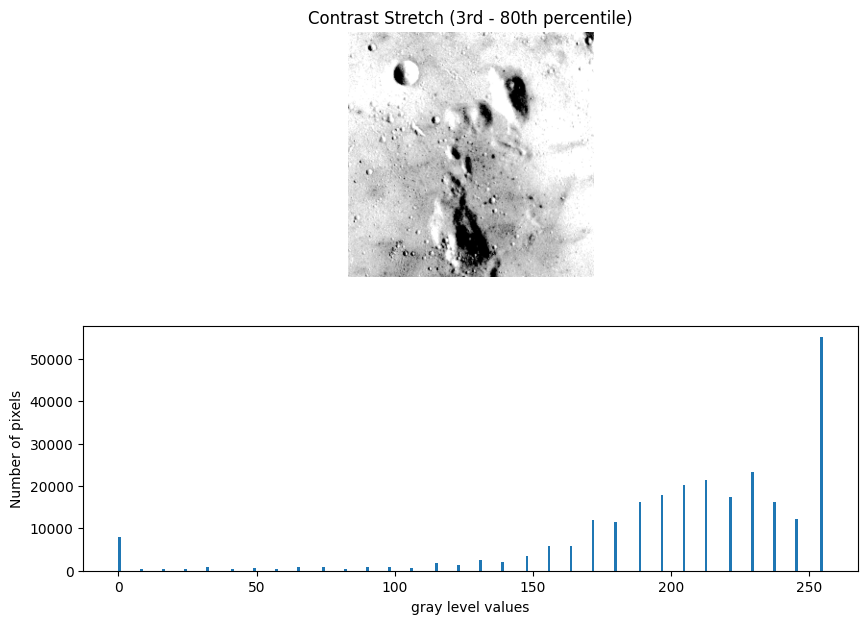

In [2]:
p3, p80 = np.percentile(img, (3, 80))
img_rescale = exposure.rescale_intensity(img, in_range=(p3, p80))

fig = plt.figure(figsize=(10, 7))

fig.add_subplot(2, 1, 1)
plt.imshow(img_rescale, cmap="gray")
plt.axis("off")
plt.title("Contrast Stretch (3rd - 80th percentile)")

fig.add_subplot(2, 1, 2)
plt.hist(img_rescale.flat, bins=256, range=(0, 255))
plt.xlabel("gray level values")
plt.ylabel("Number of pixels")

plt.show()

# Task 2:
Histogram equalization using `exposure.equalize_hist`.

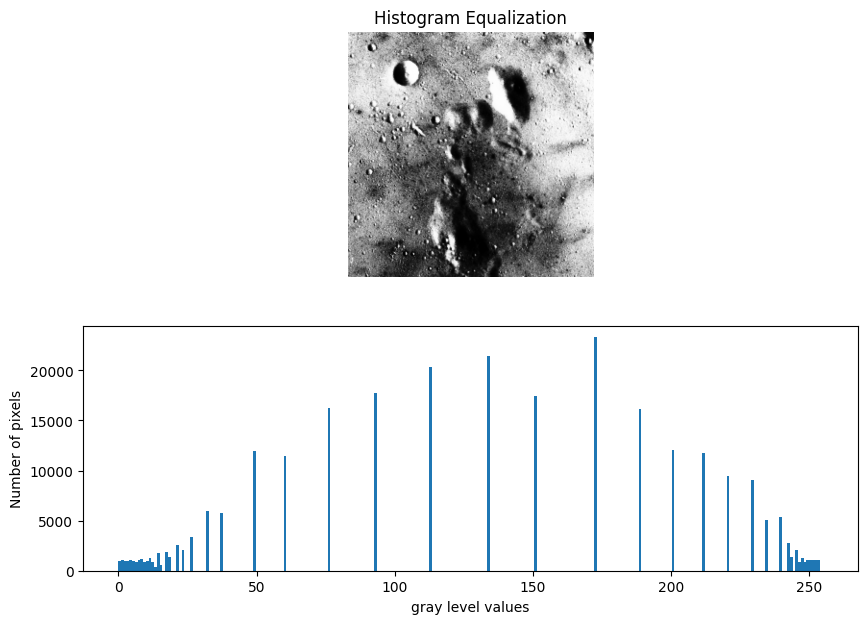

In [3]:
img_eq = exposure.equalize_hist(img)
img_eq = np.uint8(img_eq * 255)

fig = plt.figure(figsize=(10, 7))

fig.add_subplot(2, 1, 1)
plt.imshow(img_eq, cmap="gray")
plt.axis("off")
plt.title("Histogram Equalization")

fig.add_subplot(2, 1, 2)
plt.hist(img_eq.flat, bins=256, range=(0, 255))
plt.xlabel("gray level values")
plt.ylabel("Number of pixels")

plt.show()

# Task 3:
Histogram matching using the rocket image as reference and the Chelsea image as source.

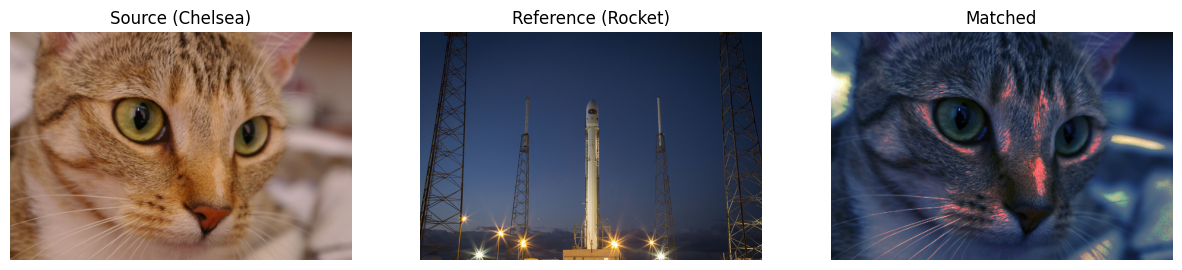

In [4]:
matched = exposure.match_histograms(source, reference, channel_axis=-1)
matched = np.uint8(np.clip(matched, 0, 255))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(source)
axes[0].set_title("Source (Chelsea)")

axes[1].imshow(reference)
axes[1].set_title("Reference (Rocket)")

axes[2].imshow(matched)
axes[2].set_title("Matched")

for ax in axes:
    ax.axis("off")

plt.show()

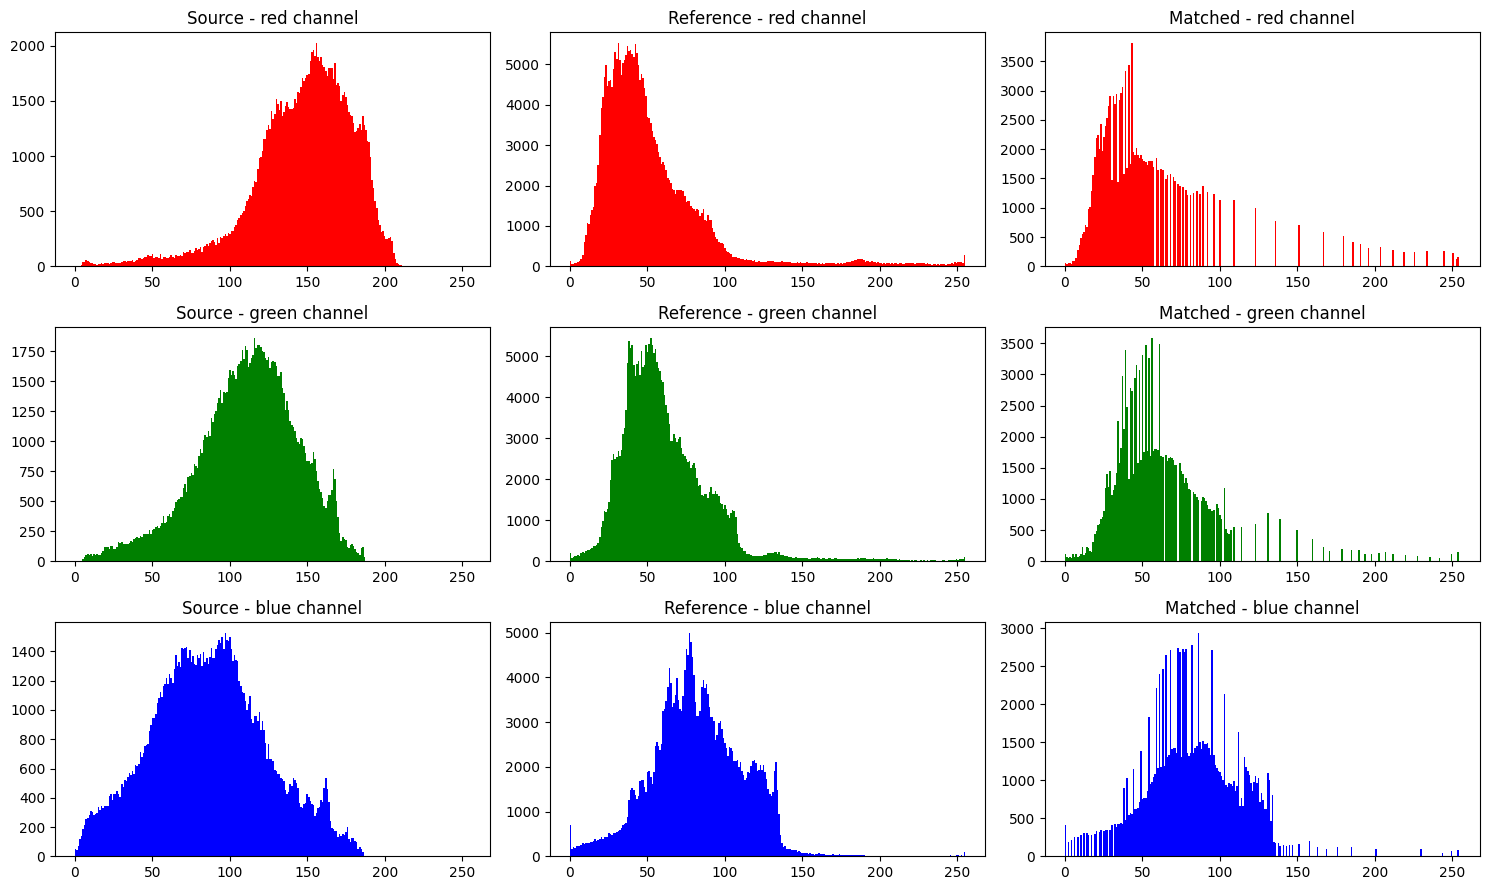

In [5]:
colors = ("red", "green", "blue")
images = (source, reference, matched)
titles = ("Source", "Reference", "Matched")

fig, axes = plt.subplots(3, 3, figsize=(15, 9))

for row, channel_color in enumerate(colors):
    for col, (image, title) in enumerate(zip(images, titles)):
        axes[row, col].hist(image[..., row].flat, bins=256, range=(0, 255), color=channel_color)
        axes[row, col].set_title(f"{title} - {channel_color} channel")

plt.tight_layout()
plt.show()